# Multi-Class Image Classification on CIFAR-10
## Problem Formulation & Empirical Setup

In this investigation, we address visual object categorization formulated as a supervised multi-class classification task over an empirical dataset $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^N$, where:
- $\mathbf{x}_i \in \mathbb{R}^{32 \times 32 \times 3}$ is a 3-channel RGB image tensor on a discrete spatial lattice.
- $y_i \in \{0, 1, \dots, K-1\}$ represents a categorical label across $K=10$ mutually exclusive classes.

The objective is to learn a parameterized mapping $f_\theta: \mathcal{X} \to \Delta^{K-1}$ (the probability simplex) via a Convolutional Neural Network (CNN) backbone with parameters $\theta$, optimized via Empirical Risk Minimization (ERM) under categorical cross-entropy loss.

In [4]:
import cv2 as cv
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras import datasets, layers, models

## 1. Dataset Ingestion: CIFAR-10 Benchmark

The CIFAR-10 dataset comprises 60,000 $32 \times 32$ natural color images uniformly distributed across 10 classes (50,000 training, 10,000 test). Due to the low spatial resolution, the dataset exhibits substantial intra-class variance, background clutter, and diverse viewpoints, making it a canonical benchmark for evaluating visual representation learning.

In [5]:
(trainings_images, trainings_labels), (test_images, test_labels) = datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3417s 20us/step


## 2. Feature Normalization & Loss Surface Conditioning

Raw 8-bit unsigned integer channels take values in $[0, 255]$. We apply a continuous affine mapping (min-max scaling):
$$\mathbf{x}_{\text{norm}} = \frac{\mathbf{x}}{255.0} \in [0.0, 1.0]^{H \times W \times C}$$

**Theoretical Motivation:**
- **Hessian Conditioning**: Unbounded or high-variance input magnitudes inflate the condition number of the Hessian $\mathbf{H} = \nabla^2 \mathcal{L}(\theta)$, inducing anisotropic contours and oscillatory gradient updates.
- **Activation Regimes**: Restricting inputs to $[0, 1]$ stabilizes early forward passes, preventing activation saturation and ensuring well-behaved variance propagation across layers under standard initialization.

In [7]:
trainings_images, test_images = trainings_images / 255.0, test_images / 255.0

## 3. Class Ontology & Qualitative Data Exploration

We define the categorical label ontology $\mathcal{Y} = \{\text{airplane}, \dots, \text{truck}\}$ mapping target indices to semantic classes. Qualitative inspection validates ground-truth alignment and visualizes inter-class separability and ambiguities (e.g., distinguishing quadruped classes like *cat* vs. *dog* at $32 \times 32$ spatial resolution).

In [8]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

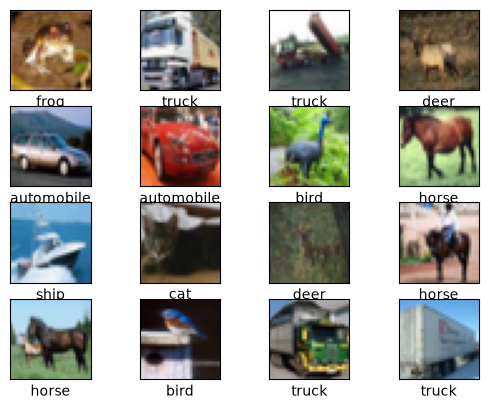

In [9]:
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(trainings_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[trainings_labels[i][0]])
plt.show()

## 4. Empirical Subsampling & Compute Budgeting

To accelerate training and reduce memory footprint during empirical prototyping, the dataset is truncated to $N = 20,000$ training and test instances.

> **Statistical Learning Note**: Subsampling reduces sample complexity, lowering epoch wall-clock time at the cost of wider generalization bounds and increased susceptibility to empirical overfitting unless offset by data augmentation or explicit regularization.

In [12]:
trainings_images = trainings_images[:20000]
trainings_labels = trainings_labels[:20000]

testing_images = test_images[:20000]
testing_labels = test_labels[:20000]

## 5. Architectural Topology & Optimization Setup

### Inductive Biases of the CNN Backbone
Unlike dense Multi-Layer Perceptrons, Convolutional Neural Networks incorporate critical spatial inductive priors:
1. **Local Connectivity (Receptive Fields)**: Exploits local pixel correlation and spatial redundancy.
2. **Translation Equivariance via Weight Sharing**: Convolution kernels sliding across the spatial lattice ensure feature detectors respond uniformly irrespective of translation: $f(T_g(\mathbf{x})) = T_g(f(\mathbf{x}))$.

### Network Topology Breakdown:
- **Feature Extraction Backbone**:
  - `Conv2D(32, 3x3, ReLU) + MaxPool2D(2x2)`: Captures low-level spatial primitives (edges, color gradients), downsampling $32 \times 32 \to 16 \times 16$.
  - `Conv2D(64, 3x3, ReLU) + MaxPool2D(2x2)`: Encodes mid-level textural motifs and sub-structural patterns ($16 \times 16 \to 8 \times 8 \to 4 \times 4$).
  - `Conv2D(64, 3x3, ReLU)`: Aggregates contextual representations with expanded receptive fields ($4 \times 4 \times 64$).
- **Classification Head**:
  - `Flatten + Dense(64, ReLU) + Dense(10, Softmax)`: Projects latent spatial embeddings to normalized posterior class probabilities: $p(y = k \mid \mathbf{x}) = \frac{\exp(z_k)}{\sum_{j=1}^{10} \exp(z_j)}$.
- **Loss Function & Optimizer**:
  - **Sparse Categorical Cross-Entropy**: Empirical negative log-likelihood over multinomial integer targets: $\mathcal{L}_{\text{CE}}(\theta) = -\frac{1}{B} \sum_{i=1}^B \log p_\theta(y_i \mid \mathbf{x}_i)$.
  - **Adam Optimizer**: Combines first-order momentum (Polyak) and second-moment gradient scaling (RMSprop) for adaptive coordinate-wise learning rates.

In [14]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

## 6. Model Training & Optimization Dynamics

We minimize empirical risk over 10 epochs using mini-batch stochastic gradient descent. Joint tracking of training and validation loss/accuracy across iterations reveals convergence rates and the emergence of the generalization gap:
$$\text{Generalization Gap} = \hat{\mathcal{R}}_{\text{val}}(\theta) - \hat{\mathcal{R}}_{\text{train}}(\theta)$$

In [15]:

model.fit(trainings_images, trainings_labels, epochs=10, validation_data=(testing_images, testing_labels))

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3526 - loss: 1.7470 - val_accuracy: 0.4848 - val_loss: 1.4370
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5069 - loss: 1.3796 - val_accuracy: 0.5361 - val_loss: 1.2941
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.5658 - loss: 1.2287 - val_accuracy: 0.5654 - val_loss: 1.2303
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6086 - loss: 1.1170 - val_accuracy: 0.5792 - val_loss: 1.2098
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6379 - loss: 1.0295 - val_accuracy: 0.5869 - val_loss: 1.1922
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.6629 - loss: 0.9516 - val_accuracy: 0.6170 - val_loss: 1.1216
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.6876 - loss: 0.8826 - val_accuracy: 0.6415 - val_loss: 1.0516
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7104 - loss: 0.8209 - val_accura

## 7. Model Evaluation & Empirical Observations

We evaluate the finalized parameters $\theta^*$ on held-out test data to obtain an unbiased estimate of generalization error:
$$\hat{\mathcal{R}}_{\text{test}}(\theta^*) = \frac{1}{N_{\text{test}}} \sum_{i=1}^{N_{\text{test}}} \mathcal{L}(f_{\theta^*}(\mathbf{x}_i), y_i)$$

### Diagnostics & Architectural Roadmap:
- **Generalization Gap**: Training accuracy rises to $\sim 75\%$ while validation/test accuracy plateaus around $\sim 64\%$. This divergence highlights classic variance error (overfitting) on non-augmented data.
- **Key Levers for Model Evolution**: Integrating spatial data augmentation (random flips/crops), regularization (Dropout, Batch Normalization), and residual skip connections (ResNet) to stabilize gradients in deeper feature hierarchies.

In [ ]:
loss, accuracy = model.evaluate(testing_images, testing_labels)
print(f"Test loss: {loss:.4f}, Test accuracy: {accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6397 - loss: 1.0843
Test loss: 1.0843, Test accuracy: 0.6397
